# Calçada Livre · Visão Computacional
**FIAP · Global Solution 2026.2 · Applied Computer Vision** — Carlos Ganzerli (RM 99840), Paulo Lopes (RM 551137), Lucas Bandeira (RM 98640), Gustavo Melo (RM 98809).

Detector YOLO26n treinado de forma customizada para três barreiras de acessibilidade em calçadas: **buraco**, **obstáculo** e **piso quebrado**. Este notebook documenta os dados, o treino, a avaliação e a inferência. Os scripts numerados em `scripts/` reproduzem cada etapa.

In [1]:
%config InlineBackend.figure_formats = ['jpeg']
import json, os, sys
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt, cv2
plt.rcParams['figure.dpi'] = 72
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'scripts'))
from common import DATASET, class_names
import torch, ultralytics
print('PyTorch', torch.__version__, '| CUDA:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
print('Ultralytics', ultralytics.__version__)
print('Classes:', class_names())

PyTorch 2.11.0+cu128 | CUDA: True NVIDIA GeForce RTX 5060
Ultralytics 8.4.215
Classes: ['buraco', 'obstaculo', 'piso_quebrado']


## 1. Dataset customizado
Dois datasets públicos (MIT) com visão de pedestre foram remapeados para a taxonomia do projeto (`configs/classes.yaml`), limpos e deduplicados por pHash antes da divisão 80/10/10.

In [2]:
stats = json.loads((ROOT/'results'/'dataset_stats.json').read_text(encoding='utf-8'))
print({k: v for k, v in stats.items() if k != 'splits'})
rows = []
for s, v in stats['splits'].items():
    rows.append({'split': s, 'imagens': v['images'], 'fundo (sem barreira)': v['background'], **v['instances']})
pd.DataFrame(rows).set_index('split')

{'candidatas': 9253, 'corrompidas_removidas': 0, 'duplicatas_exatas_removidas': 1754, 'grupos_de_quase_duplicatas': 7139, 'descartadas_na_leitura': {'so_classes_descartadas': 1140, 'rotulo_corrompido': 1, 'caixa_gigante': 19}, 'final': 7499, 'oversampling_treino': {'piso_quebrado': 3}}


,imagens,fundo (sem barreira),obstaculo,buraco,piso_quebrado
split,,,,,
train,6001,401,6376,1231,328
val,749,50,805,154,51
test,749,50,755,178,37


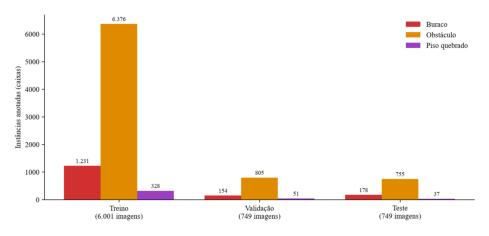

In [3]:
img = plt.imread(ROOT/'results'/'figuras'/'dataset_distribuicao.png')
plt.figure(figsize=(10,4)); plt.imshow(img); plt.axis('off');

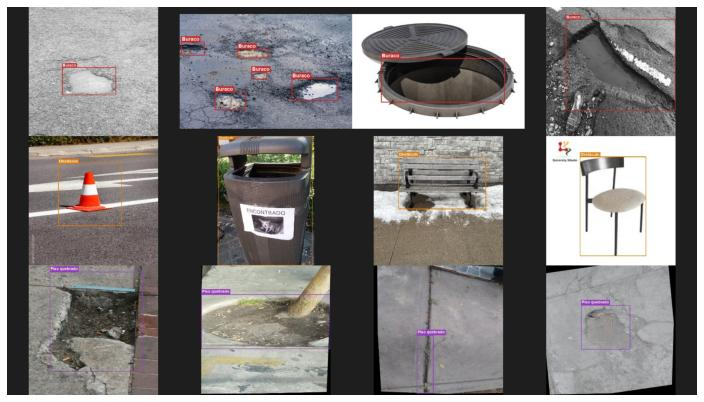

In [4]:
img = plt.imread(ROOT/'results'/'figuras'/'dataset_amostras.jpg')
plt.figure(figsize=(14,7)); plt.imshow(img); plt.axis('off');

## 2. Treino (fine-tuning a partir do COCO)
Curvas de perda e de métricas de validação por época.

{'modelo_base': 'yolo26n.pt', 'epocas_max': 100, 'epocas_executadas': 100, 'imgsz': 640, 'batch': 32, 'tempo_treino_min': 83.6, 'run_dir': 'runs/yolo26n_calcada', 'observacao': 'treino interrompido na Ã©poca 61 e retomado do last.pt (resume=True), sem perda de estado do otimizador'}


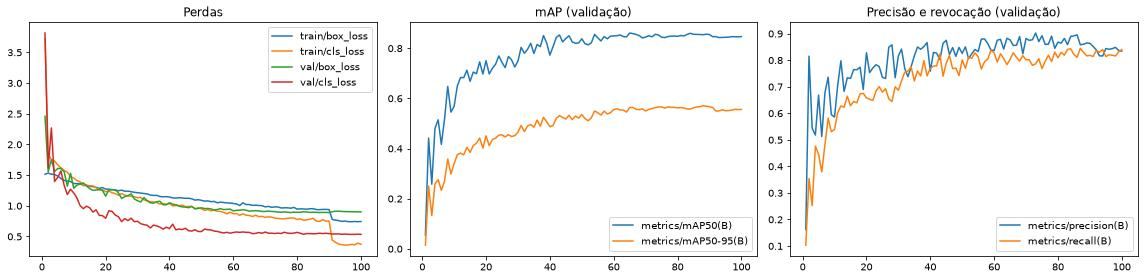

In [5]:
df = pd.read_csv(ROOT/'results'/'treino'/'yolo26n_calcada'/'results.csv'); df.columns = [c.strip() for c in df.columns]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for c in ['train/box_loss','train/cls_loss','val/box_loss','val/cls_loss']:
    if c in df: ax[0].plot(df['epoch'], df[c], label=c)
ax[0].set_title('Perdas'); ax[0].legend()
for c in ['metrics/mAP50(B)','metrics/mAP50-95(B)']: ax[1].plot(df['epoch'], df[c], label=c)
ax[1].set_title('mAP (validação)'); ax[1].legend()
for c in ['metrics/precision(B)','metrics/recall(B)']: ax[2].plot(df['epoch'], df[c], label=c)
ax[2].set_title('Precisão e revocação (validação)'); ax[2].legend()
plt.tight_layout(); print(json.loads((ROOT/'results'/'treino'/'yolo26n_calcada'/'train_info.json').read_text()))

## 3. Avaliação do modelo final no conjunto de teste
Imagens que o modelo nunca viu. IoU 0,5 para mAP50; 0,5–0,95 para mAP50-95.

In [6]:
m = json.loads((ROOT/'results'/'calcada_yolo26n'/'metrics.json').read_text(encoding='utf-8'))
print('Geral:', m['geral'])
print('Velocidade:', m['velocidade'])
pd.DataFrame(m['por_classe']).T

Geral: {'precisao': 0.8903, 'revocacao': 0.8142, 'mAP50': 0.8516, 'mAP50_95': 0.6038}
Velocidade: {'fps_gpu_batch1': 60.6, 'fps_cpu_batch1': 24.9, 'gpu': 'NVIDIA GeForce RTX 5060', 'ms_por_imagem_val': {'preprocess': 0.91, 'inference': 2.71, 'loss': 0.0, 'postprocess': 1.31}}


,precisao,revocacao,mAP50,mAP50_95
buraco,0.7989,0.6696,0.7207,0.4085
obstaculo,0.9310,0.9110,0.9526,0.8087
piso_quebrado,0.9410,0.8619,0.8814,0.5940


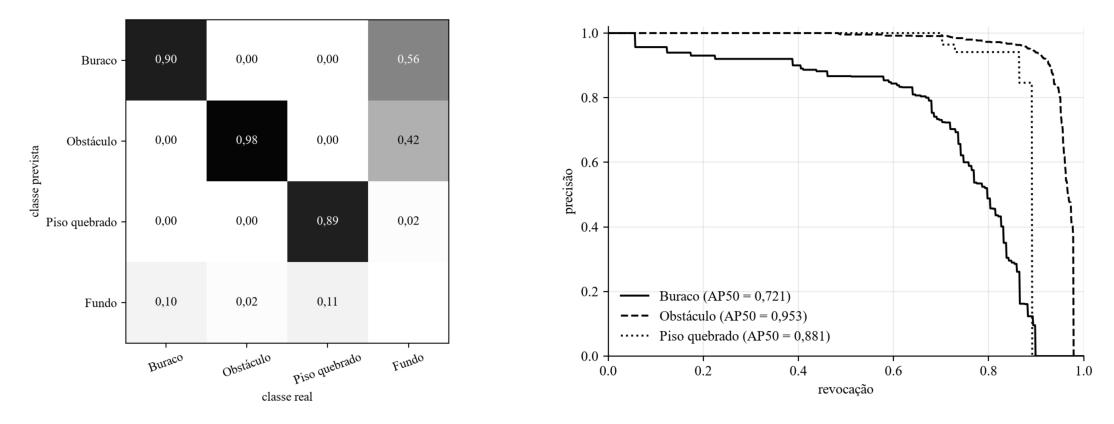

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].imshow(plt.imread(ROOT/'results'/'figuras'/'matriz_confusao.png')); ax[0].axis('off')
ax[1].imshow(plt.imread(ROOT/'results'/'figuras'/'curva_pr.png')); ax[1].axis('off'); plt.tight_layout()

### Comparação de arquiteturas (mesmo dataset, mesma receita)

In [8]:
print((ROOT/'results'/'comparacao.md').read_text(encoding='utf-8'))

| Modelo | Precisão | Revocação | mAP50 | mAP50-95 | FPS GPU | FPS CPU | Tamanho |
|---|---|---|---|---|---|---|---|
| calcada_yolo26n | 0.890 | 0.814 | 0.852 | 0.604 | 60.6 | 24.9 | 5.46 MB |
| calcada_yolo26n_base | 0.880 | 0.821 | 0.860 | 0.599 | 62.7 | 27.2 | 5.47 MB |
| calcada_yolo11n | 0.826 | 0.804 | 0.845 | 0.586 | 67.3 | 26.0 | 5.52 MB |



## 4. Exemplos de acerto e de erro (gabarito × predição)

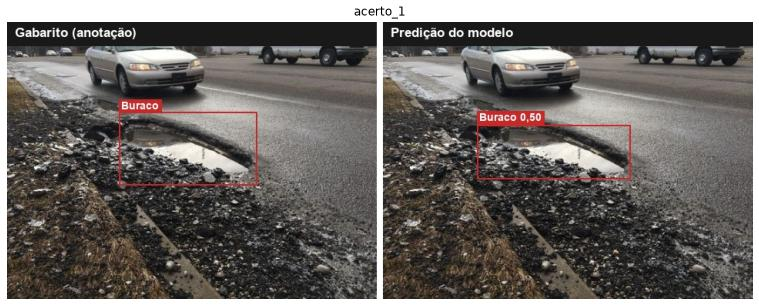

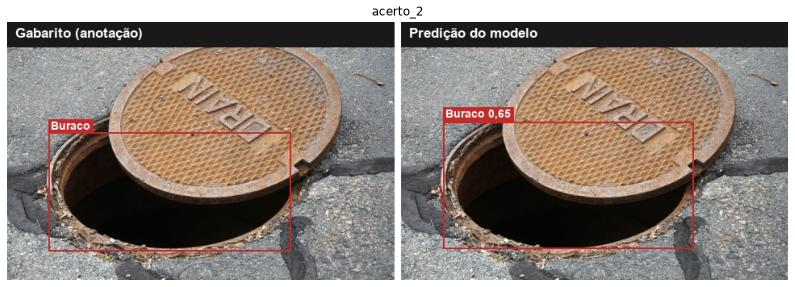

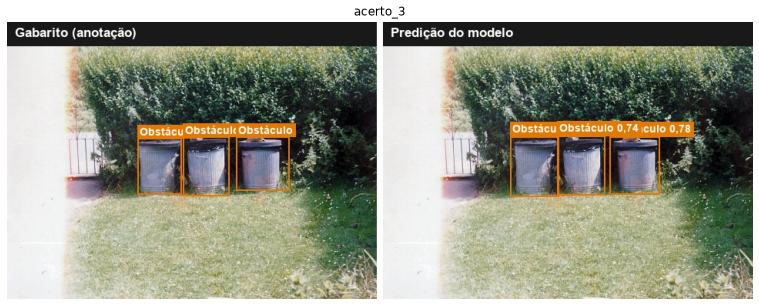

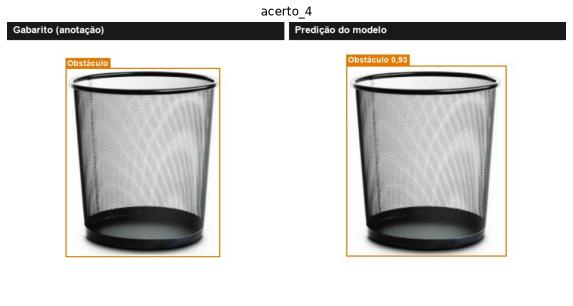

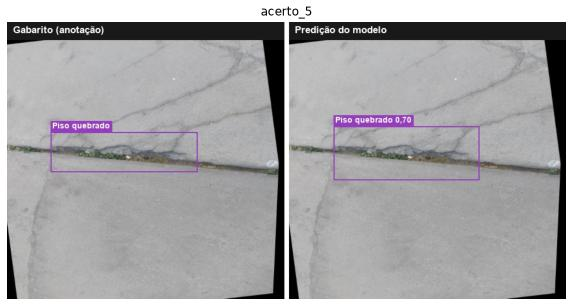

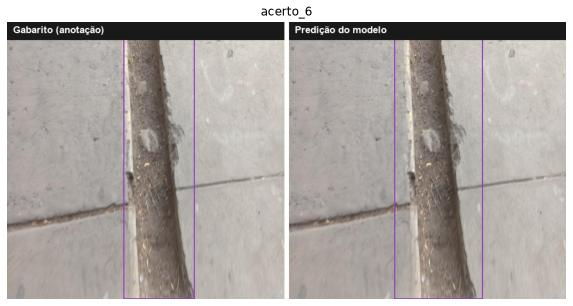

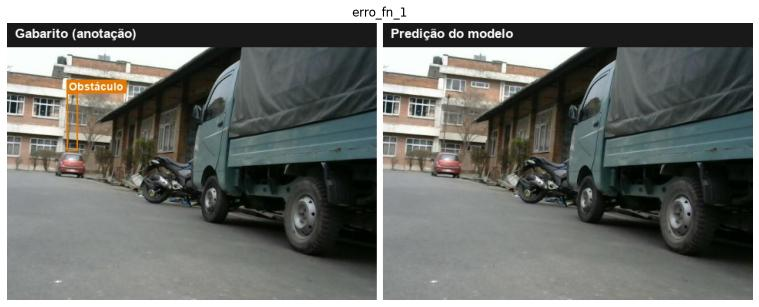

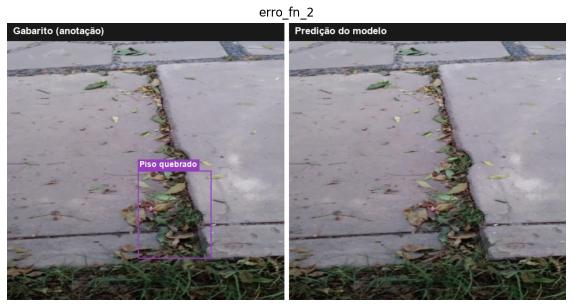

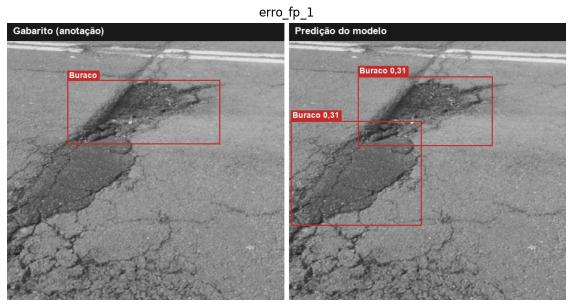

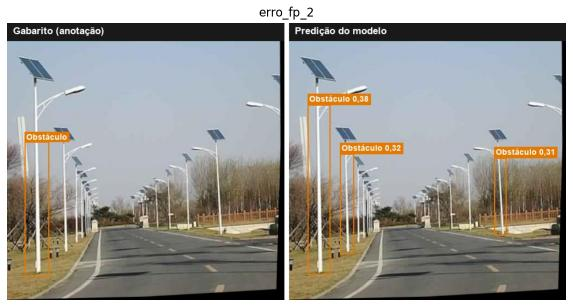

In [9]:
ex = sorted((ROOT/'results'/'calcada_yolo26n'/'exemplos').glob('*.jpg'))
for p in ex:
    plt.figure(figsize=(14, 5)); plt.imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)); plt.title(p.stem); plt.axis('off')

## 5. Calçadas brasileiras: teste fora da distribuição e adaptação de domínio
Vídeos reais da Bela Vista, São Paulo (Wikimedia Commons, CC BY 3.0). Cada vídeo foi dividido no tempo: início para adaptação (fine-tuning), intervalo descartado e final como **teste brasileiro**, nunca usado no treino. O modelo só treinado com datasets estrangeiros quase não reconhecia o piso quebrado brasileiro; a tabela mostra o efeito da adaptação nos dois conjuntos de teste.

In [10]:
ad = json.loads((ROOT/'results'/'adaptacao_br.json').read_text(encoding='utf-8'))
print({k: ad[k] for k in ('quadros_adaptacao','oversampling','quadros_teste_brasil','epocas')})
rows = []
for fase in ('antes','depois'):
    for conj in ('teste_original','teste_brasil'):
        rows.append({'modelo': fase + ' da adaptação', 'teste': conj, **ad[fase][conj]['geral']})
pd.DataFrame(rows)

{'quadros_adaptacao': 157, 'oversampling': 4, 'quadros_teste_brasil': 55, 'epocas': 40}


,modelo,teste,precisao,revocacao,mAP50,mAP50_95
0,antes da adaptação,teste_original,0.8803,0.8205,0.8600,0.5987
1,antes da adaptação,teste_brasil,0.8370,0.3812,0.3864,0.3042
2,depois da adaptação,teste_original,0.8903,0.8142,0.8516,0.6038
3,depois da adaptação,teste_brasil,0.5226,0.5474,0.5269,0.4198


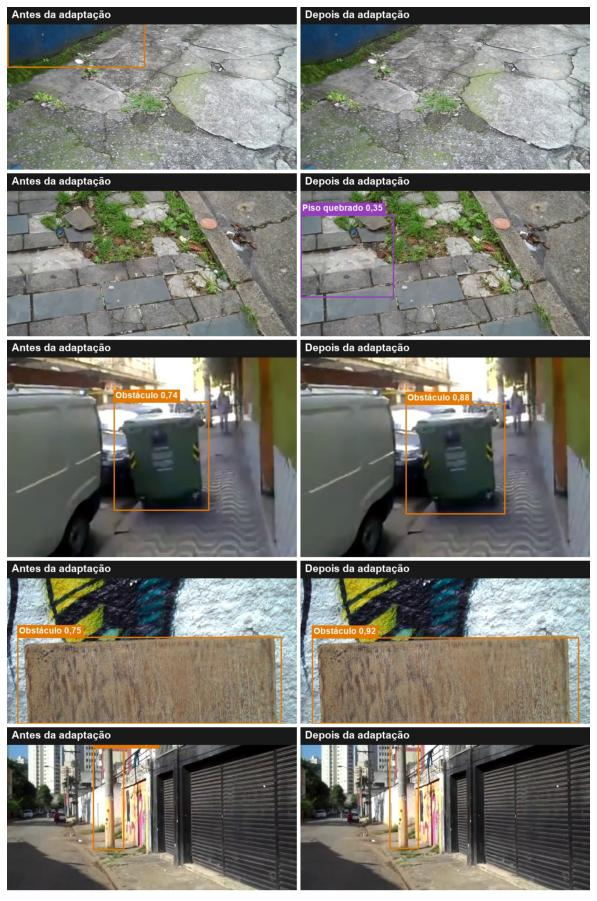

In [11]:
img = plt.imread(ROOT/'results'/'figuras'/'adaptacao_antes_depois.jpg')
plt.figure(figsize=(14,16)); plt.imshow(img); plt.axis('off');

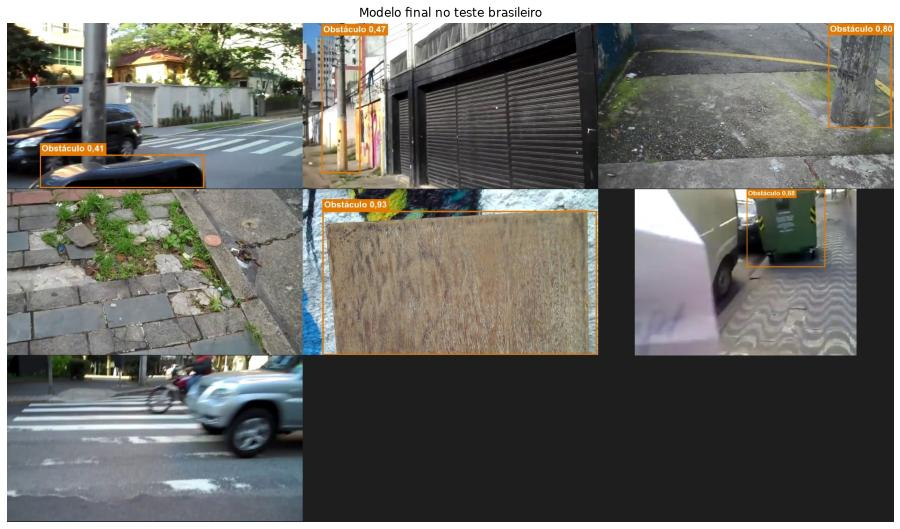

In [12]:
img = plt.imread(ROOT/'results'/'figuras'/'sao_paulo_quadros.jpg')
plt.figure(figsize=(16,9)); plt.imshow(img); plt.axis('off'); plt.title('Modelo final no teste brasileiro');

## 6. Integração com o MVP: chamada real ao endpoint `/detectar`

2026-11-17 18:33:17,776 INFO calcada.visao Modelo carregado: calcada_yolo26n.pt


2026-11-17 18:33:18,113 INFO calcada.visao ocorrencia CL-20261117-9A6CD7 origem=app tipo=buraco conf=0.56 status=pendente_validacao


2026-11-17 18:33:18,114 INFO httpx2 HTTP Request: POST http://testserver/detectar "HTTP/1.1 201 Created"


2026-11-17 18:33:18,122 INFO httpx2 HTTP Request: GET http://testserver/ocorrencias/1/foto "HTTP/1.1 200 OK"


201 Possível buraco identificado. Uma pessoa da equipe vai confirmar antes do encaminhamento.
{'protocolo': 'CL-20261117-9A6CD7', 'tipo': 'buraco', 'confianca': 0.5577, 'prioridade': 'alta', 'status': 'pendente_validacao'}


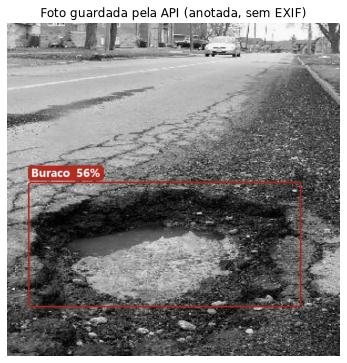

In [13]:
import tempfile
os.environ['DB_PATH'] = str(Path(tempfile.mkdtemp())/'nb.db')
os.environ['PHOTOS_DIR'] = str(Path(tempfile.mkdtemp()))
os.chdir(ROOT)
from fastapi.testclient import TestClient
from api.main import app
foto = sorted((ROOT/'samples').glob('buraco_*.jpg'))[0]
with TestClient(app) as c:
    r = c.post('/detectar', files={'foto': (foto.name, foto.read_bytes(), 'image/jpeg')}, data={'latitude': -23.5614, 'longitude': -46.6559})
    body = r.json(); print(r.status_code, body['mensagem'])
    o = body['ocorrencia']; print({k: o[k] for k in ('protocolo','tipo','confianca','prioridade','status')})
    import numpy as np
    im = cv2.imdecode(np.frombuffer(c.get(o['foto_url']).content, np.uint8), cv2.IMREAD_COLOR)
plt.figure(figsize=(8,6)); plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.title('Foto guardada pela API (anotada, sem EXIF)');